In [12]:
import sys
import json

import numpy as np
import cv2
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Polygon

sys.path.append("../../PG_PyTraining")
from common.pg.pg_geometry import PgCamera, PgDetectionArea
from common.pg.cam_params import get_camparams

sys.path.append('../gw_prototype')
from fisheye_camera import CameraCalibrationParameters
from detection_area import CameraConfiguration, DetectionArea

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [15]:
CAMERA_H = 260

In [17]:
base_camera = PgCamera(CAMERA_H * 10, "Cam3")

da = PgDetectionArea(cam=base_camera)
cam_params = get_camparams("Cam3")

In [19]:
poly_cm = da.get_cm_polygon()
poly_px = da.polygon_in_pixels()

In [23]:
np.abs(poly_cm[0][0] * 2), np.abs(poly_cm[0][1] * 2)

(773.0, 449.0)

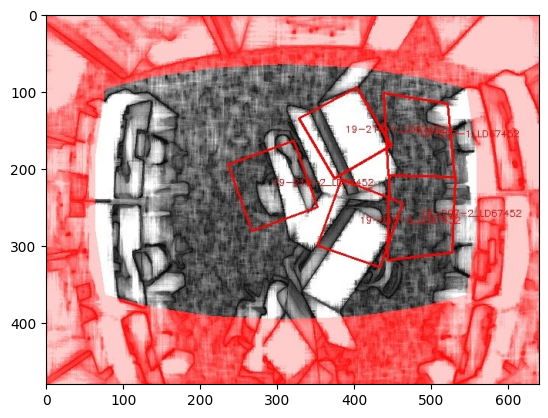

In [6]:
img = cv2.imread("SKETCH_data_PG-L18-38.jpg")
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
plt.imshow(img)


149.43843225904652


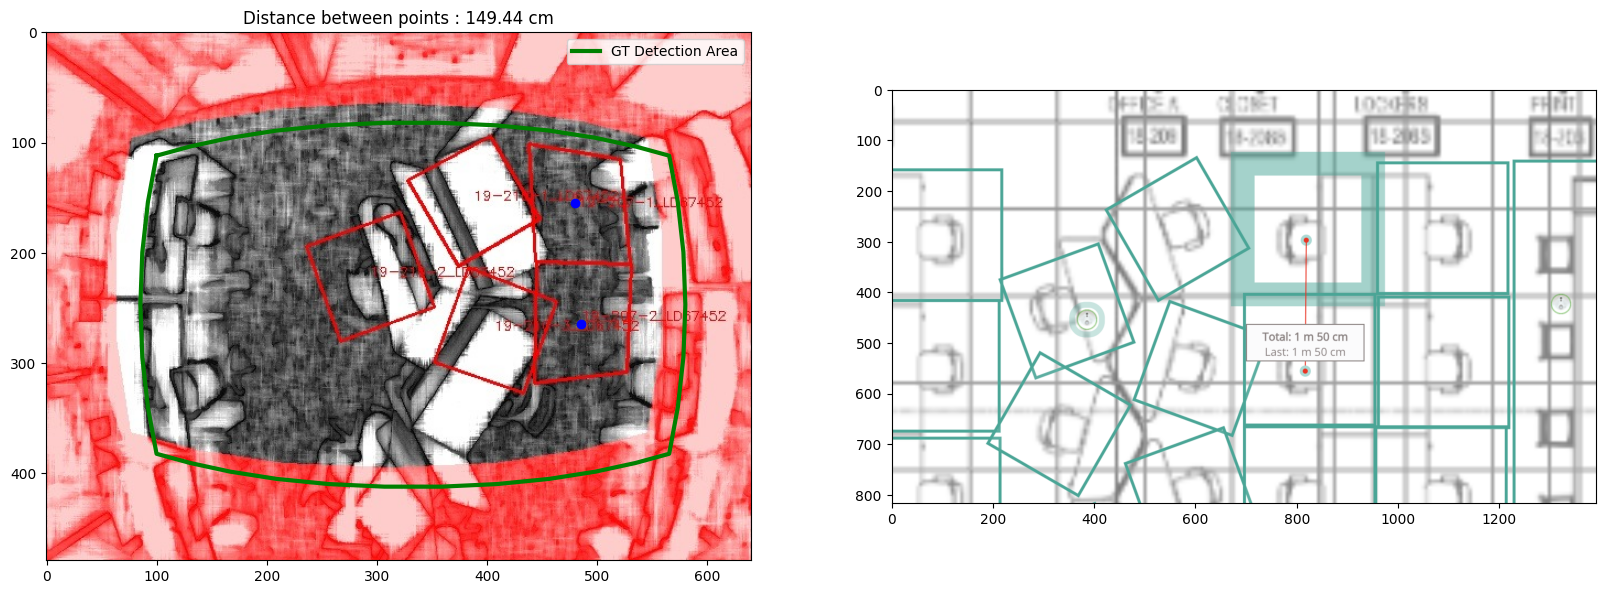

In [55]:
a = 480, 155
b = 485, 265

plt.figure(figsize=(20, 10))

plt.subplot(1, 2, 1)
plt.imshow(img)
plt.plot(poly_px[:, 0], poly_px[:, 1], "g-", linewidth=3, label="GT Detection Area")
plt.legend()

plt.plot(a[0], a[1], "bo", label="Example Point")
plt.plot(b[0], b[1], "bo", label="Example Point")

plt.plot()

a_cm = base_camera.pixel2cm([a])[0]
b_cm = base_camera.pixel2cm([b])[0]
print(np.linalg.norm(a_cm - b_cm))
plt.title(f"Distance between points : {np.linalg.norm(a_cm - b_cm):.2f} cm")

plt.subplot(1, 2, 2)
gt_img = cv2.imread("Screenshot 2026-03-06 at 15.28.31.png")
gt_img = cv2.cvtColor(gt_img, cv2.COLOR_BGR2RGB)
plt.imshow(gt_img)

156.51814237918623


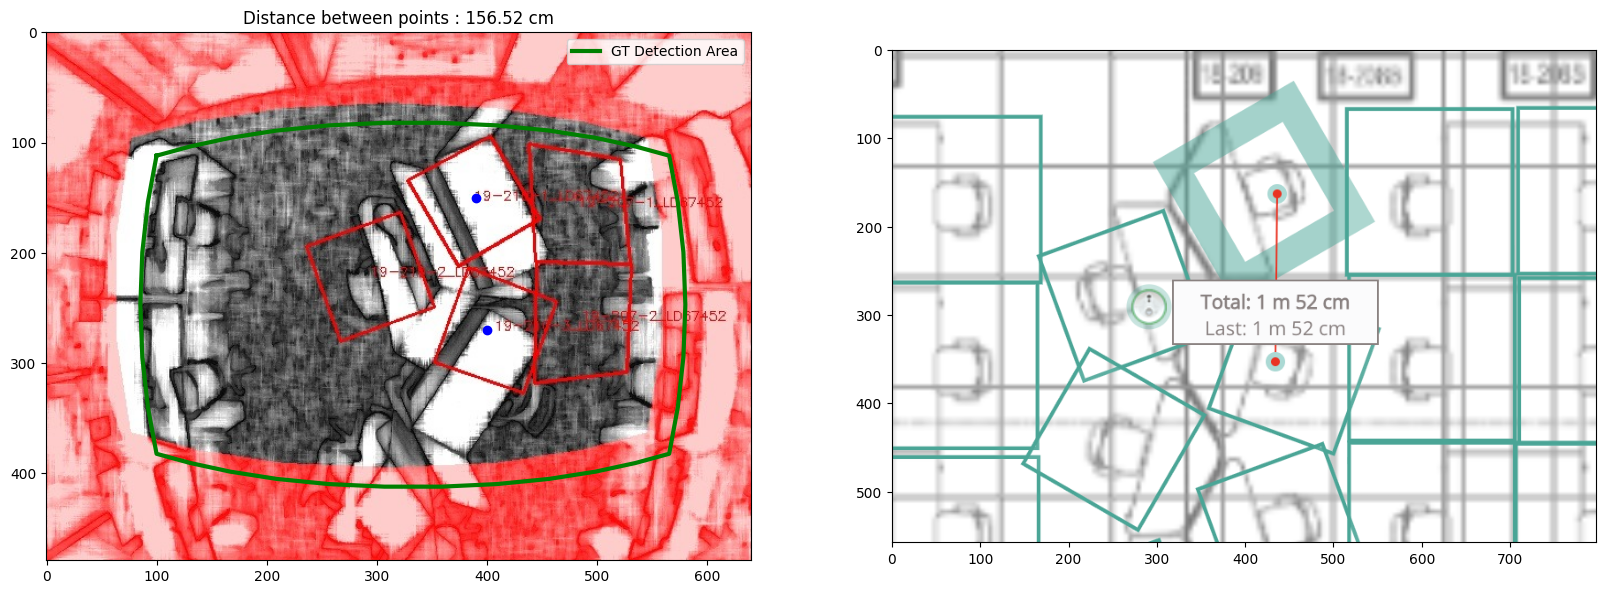

In [57]:
a = 390, 150
b = 400, 270


plt.figure(figsize=(20, 10))

plt.subplot(1, 2, 1)
plt.imshow(img)
plt.plot(poly_px[:, 0], poly_px[:, 1], "g-", linewidth=3, label="GT Detection Area")
plt.legend()

plt.plot(a[0], a[1], "bo", label="Example Point")
plt.plot(b[0], b[1], "bo", label="Example Point")

plt.plot()

a_cm = base_camera.pixel2cm([a])[0]
b_cm = base_camera.pixel2cm([b])[0]
print(np.linalg.norm(a_cm - b_cm))
plt.title(f"Distance between points : {np.linalg.norm(a_cm - b_cm):.2f} cm")

plt.subplot(1, 2, 2)
gt_img = cv2.imread("Screenshot 2026-03-06 at 15.00.12.png")
gt_img = cv2.cvtColor(gt_img, cv2.COLOR_BGR2RGB)
plt.imshow(gt_img)